# Batches

Thousands of shapes from numpy arrays: a scatter plot of 20,000 points coloured by a colormap, then a
particle field of arrows that move, turn and fade one by one, all made, transformed and written as columns.

    python batches.py                writes 21_scatter.svg, 21_scatter.png, 21_field.svg and 21_field.png

In [1]:
import numpy as np

import svgwriter as svg

Two clusters of 10,000 points each. `svg.batch.points` takes the coordinate arrays as they are; the
colormap turns each point's distance from the centre into a colour, and the shared opacity applies to
every dot, so dense regions come out darker.

In [2]:
rng = np.random.default_rng(21)
x = np.concatenate([rng.normal(170, 45, 10_000), rng.normal(330, 30, 10_000)])
y = np.concatenate([rng.normal(220, 60, 10_000), rng.normal(150, 35, 10_000)])
distance = np.hypot(x - 250, y - 200)

plot = svg.Document(500, 400)
plot.rect(0, 0, 500, 400, fill="#fbfbf8")
dots = plot.add(svg.batch.points(x, y, 2.2, fill=svg.batch.colormap("viridis", distance), opacity=0.55))
print(len(dots), "points,", len(plot.to_string()) // 1024, "KiB of SVG")

20000 points, 1556 KiB of SVG


Axes and labels are ordinary elements; a batch of lines draws the ticks and a batch of texts their labels.
The plot is 1.5 MB of SVG, so it is shown here as a picture: its pixels, rendered at 40%, in an `svg.Image`.

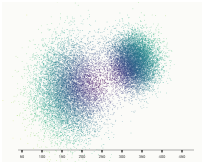

In [3]:
ticks = np.arange(50, 500, 50)
plot.line(40, 370, 480, 370, stroke="#333")
plot.add(svg.batch.lines(ticks, 370, ticks, 376, stroke="#333"))
plot.add(svg.batch.texts([str(t) for t in ticks], ticks, 390, font_size=10, text_anchor="middle", fill="#333"))
plot.save("21_scatter.svg")
plot.save("21_scatter.png")
svg.Image(plot.rasterize(scale=0.4))

A particle field: one arrow repeated 1,500 times with `svg.batch.instances`. Each copy sits on a spiral,
turns along it and takes a colour from the plasma map.

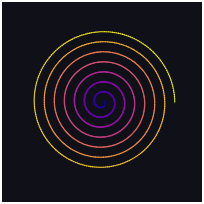

In [4]:
count = 1500
turn = np.linspace(0, 14 * np.pi, count)
radius = 6 + turn * 4
arrow = svg.polygon([(-4, -2), (4, 0), (-4, 2)])
field = svg.Document(500, 500)
field.rect(0, 0, 500, 500, fill="#101018")
particles = field.add(svg.batch.instances(arrow, 250 + radius * np.cos(turn), 250 + radius * np.sin(turn),
                                          angle=np.degrees(turn) + 90, fill=svg.batch.colormap("plasma", turn)))
svg.Image(field.rasterize(scale=0.4))

Vectorized transforms move every particle by its own amount: a radial push that grows outwards, a
random turn and a size that shrinks towards the centre. `set` fades the inner particles.

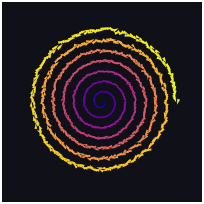

In [5]:
push = rng.uniform(0, 1, count) * radius / 20
particles.translate(push * np.cos(turn), push * np.sin(turn))
particles.rotate(rng.normal(0, 15, count))
particles.scale(np.linspace(0.6, 1.8, count))
particles.set(opacity=np.clip(radius / radius.max() + 0.2, 0, 1))
field.save("21_field.png")
svg.Image(field.rasterize(scale=0.4))

Reading an item turns the batch into real elements, which then edit and animate like any other. Here
30 large particles on the outer turn fade in one after another with a staggered preset; the SVG plays it.

False 30 gold


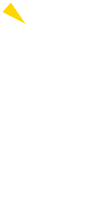

In [6]:
tail = svg.batch.instances(arrow, 250 + radius[-30:] * np.cos(turn[-30:]), 250 + radius[-30:] * np.sin(turn[-30:]),
                           angle=np.degrees(turn[-30:]) + 90, scale=2.5, fill="white")
tail.animate.fade_in(0.4, stagger=0.05)
tail[0].fill = "gold"
field.add(tail)
field.save("21_field.svg")
print(tail.compact, len(tail), tail[0].get("fill"))
tail